## 1. Setup

### 1.1 Environment Setup and Imports

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent.parent.parent
sys.path.insert(0, str(project_root))
print("Project root:", project_root)

Project root: /home/verve/Project/research/MorphCell


In [2]:
import umap
import numpy as np
from sklearn.decomposition import PCA

/home/verve/Project/research/MorphCell/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 Configuration

In [3]:
# random seed
seed = 42
np.random.seed(seed)

FEATURE_DIR = project_root / "outputs/experiments/rbc/features/morphcell_cross+self"
OUTPUT_DIR = project_root / "outputs/experiments/rbc/manifold"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

label2name = {
    0: "discocyte",
    1: "echinocyte1",
    2: "echinocyte2",
    3: "echinocyte3",
    4: "stomatocyte",
    5: "spherocyte",
    6: "knizocyte",
}

print(f"Feature dir: {FEATURE_DIR}")
print(f"Output dir: {OUTPUT_DIR}")

Feature dir: /home/verve/Project/research/MorphCell/outputs/experiments/rbc/features/morphcell_cross+self
Output dir: /home/verve/Project/research/MorphCell/outputs/experiments/rbc/manifold


## 2. Load Exported MorphCell Features

Run `../01_feature_extraction/morphcell.ipynb` first if these files do not exist.

In [4]:
required_feature_files = [
    "ids.npy",
    "names.npy",
    "labels.npy",
    "scales.npy",
    "cls_features.npy",
    "patch_features.npy",
    "concated_features.npy",
]

missing_files = [
    name for name in required_feature_files if not (FEATURE_DIR / name).exists()
]
if missing_files:
    raise FileNotFoundError(
        "Missing exported feature files: "
        + ", ".join(missing_files)
        + "\nRun ../01_feature_extraction/morphcell.ipynb first."
    )

print("✓ All exported feature files found")

✓ All exported feature files found


### 2.1 Load Feature Arrays

In [5]:
ids = np.load(FEATURE_DIR / "ids.npy").astype(str).tolist()
names = np.load(FEATURE_DIR / "names.npy").astype(str).tolist()
labels = np.load(FEATURE_DIR / "labels.npy")
scales = np.load(FEATURE_DIR / "scales.npy")
cls_features = np.load(FEATURE_DIR / "cls_features.npy")
patch_features = np.load(FEATURE_DIR / "patch_features.npy")
concated_features = np.load(FEATURE_DIR / "concated_features.npy")

# Select which RBC classes to include in this manifold.
# Use None or [] to keep all classes.
SELECTED_CLASS_NAMES = None
# SELECTED_CLASS_NAMES = ["discocyte", "echinocyte1", "echinocyte2", "echinocyte3"]

name2label = {name: label for label, name in label2name.items()}
if SELECTED_CLASS_NAMES:
    unknown_names = [name for name in SELECTED_CLASS_NAMES if name not in name2label]
    if unknown_names:
        raise ValueError(
            f"Unknown class names: {unknown_names}. "
            f"Available classes: {list(name2label)}"
        )

    selected_labels = np.array([name2label[name] for name in SELECTED_CLASS_NAMES])
    keep_mask = np.isin(labels, selected_labels)

    ids = [id_ for id_, keep in zip(ids, keep_mask) if keep]
    names = [name for name, keep in zip(names, keep_mask) if keep]
    labels = labels[keep_mask]
    scales = scales[keep_mask]
    cls_features = cls_features[keep_mask]
    patch_features = patch_features[keep_mask]
    concated_features = concated_features[keep_mask]
    label2name = {label: label2name[label] for label in selected_labels.tolist()}
else:
    selected_labels = np.array(sorted(label2name))
    SELECTED_CLASS_NAMES = [label2name[label] for label in selected_labels]

print("\nFeature arrays loaded!")
print(f"Selected classes: {SELECTED_CLASS_NAMES}")
print(f"IDs: {len(ids)}")
print(f"Names: {len(names)}")
print(f"Labels shape: {labels.shape}")
print(f"Scales shape: {scales.shape}")
print(f"CLS features shape: {cls_features.shape}")
print(f"Patch features shape: {patch_features.shape}")
print(f"Concated features shape: {concated_features.shape}")
print(f"Unique labels: {np.unique(labels)}")


Feature arrays loaded!
Selected classes: ['discocyte', 'echinocyte1', 'echinocyte2', 'echinocyte3', 'stomatocyte', 'spherocyte', 'knizocyte']
IDs: 620
Names: 620
Labels shape: (620,)
Scales shape: (620,)
CLS features shape: (620, 384)
Patch features shape: (620, 64, 384)
Concated features shape: (620, 768)
Unique labels: [0 1 2 3 4 5 6]


## 3 PCA Analysis

### 3.1 Apply PCA

In [6]:
# PCA configuration
PCA_COMPONENTS = 50

In [7]:
# Apply PCA to combined features
print(
    f"Applying PCA to concatenated features ({cls_features.shape[1]} → {PCA_COMPONENTS} dims)..."
)
pca = PCA(n_components=PCA_COMPONENTS, random_state=seed)
features_pca = pca.fit_transform(cls_features)

# Calculate statistics for each PC
pc_means = features_pca.mean(axis=0)
pc_stds = features_pca.std(axis=0)

# Print summary
print(f"\n✓ PCA completed!")
print(f"  Original shape: {cls_features.shape}")
print(f"  PCA shape: {features_pca.shape}")
print(f"  Total explained variance: {pca.explained_variance_ratio_.sum():.2%}")
print(f"\nTop 5 PC statistics:")
for i in range(5):
    print(
        f"  PC{i+1}: mean={pc_means[i]:.4f}, std={pc_stds[i]:.4f}, "
        f"explained variance={pca.explained_variance_ratio_[i]:.2%}"
    )

Applying PCA to concatenated features (384 → 50 dims)...

✓ PCA completed!
  Original shape: (620, 384)
  PCA shape: (620, 50)
  Total explained variance: 94.35%

Top 5 PC statistics:
  PC1: mean=0.0000, std=0.3099, explained variance=29.44%
  PC2: mean=0.0000, std=0.2046, explained variance=12.84%
  PC3: mean=0.0000, std=0.1410, explained variance=6.09%
  PC4: mean=0.0000, std=0.1281, explained variance=5.03%
  PC5: mean=-0.0000, std=0.1230, explained variance=4.64%


In [8]:
from utils import plot_2d_scatter

plot_2d_scatter(
    features_2d=features_pca[:, :2],
    labels=labels,
    label2name=label2name,
    ids=ids,
    names=names,
)

### 3.2 Visualize Explained Variance

✓ Variance plot saved to: /home/verve/Project/research/MorphCell/outputs/experiments/rbc/manifold/pca_variance.png


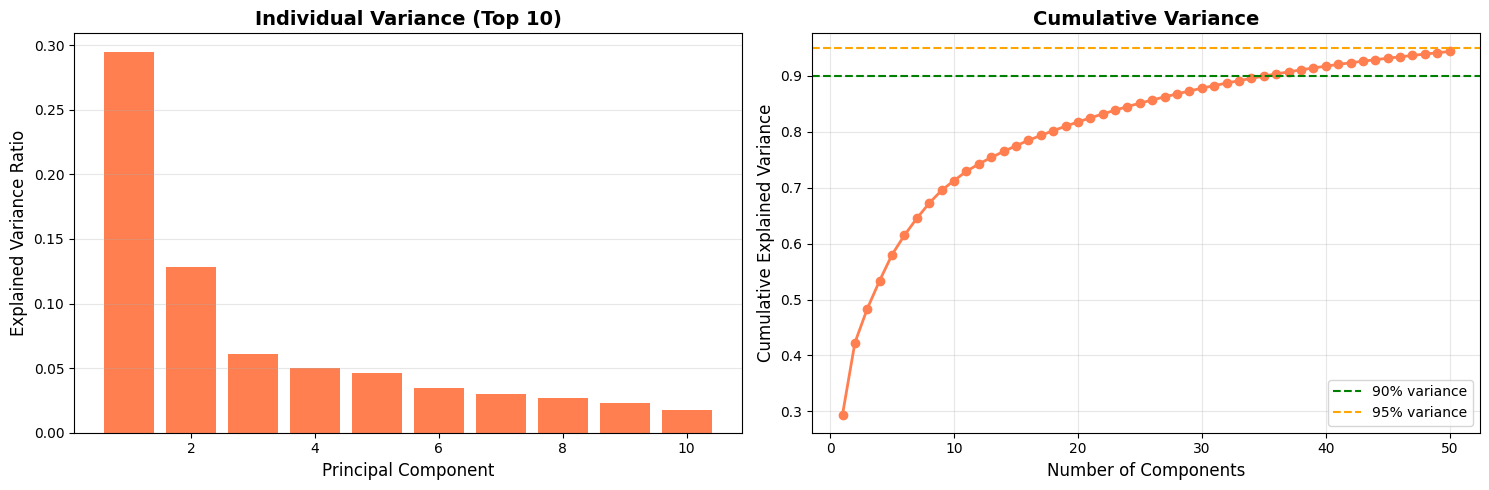

In [9]:
# Visualize explained variance using utility function
from utils import plot_pca_variance

plot_pca_variance(pca, save_path=OUTPUT_DIR / "pca_variance.png")

### 3.3 Feature Fusion: PCA + Scale

Fuse geometric features (PCA) with scale information to capture both shape and size variations.

$$F_{final} = Concat(F_{pca}, \lambda \cdot S_{normalized})$$

In [10]:
# Configuration
PCA_DIMS_TO_USE = 30  # ~85% variance
LAMBDA_WEIGHT = 0.0  # Scale weight parameter

In [11]:
from sklearn.preprocessing import StandardScaler

# Select first N PCA components
features_pca_selected = features_pca[:, :PCA_DIMS_TO_USE]

# Standardize scale factors only
scaler_scale = StandardScaler()
scales_normalized = scaler_scale.fit_transform(scales.reshape(-1, 1))

# Fuse features: [PCA features | λ * normalized scale]
features_fused = np.concatenate(
    [features_pca_selected, LAMBDA_WEIGHT * scales_normalized], axis=1
)

In [12]:
print(f"Feature Fusion Configuration:")
print(
    f"  PCA dimensions: {PCA_DIMS_TO_USE} (preserves {pca.explained_variance_ratio_[:PCA_DIMS_TO_USE].sum():.2%} variance)"
)
print(f"  Scale weight (λ): {LAMBDA_WEIGHT}")
print(f"  Fused feature shape: {features_fused.shape}")

print(
    f"  Standard deviations (σ): {np.sqrt(pca.explained_variance_[:PCA_DIMS_TO_USE])[:5]}"
)

print(f"\nFeature Statistics:")
print(
    f"  PCA range: [{features_pca_selected.min():.4f}, {features_pca_selected.max():.4f}]"
)
print(
    f"  Normalized scale range: [{scales_normalized.min():.4f}, {scales_normalized.max():.4f}]"
)
print(
    f"  Weighted scale range: [{(LAMBDA_WEIGHT * scales_normalized).min():.4f}, {(LAMBDA_WEIGHT * scales_normalized).max():.4f}]"
)

Feature Fusion Configuration:
  PCA dimensions: 30 (preserves 87.79% variance)
  Scale weight (λ): 0.0
  Fused feature shape: (620, 31)
  Standard deviations (σ): [0.31011096 0.20479551 0.14109395 0.12821396 0.12306049]

Feature Statistics:
  PCA range: [-0.5369, 0.5254]
  Normalized scale range: [-2.0743, 3.7044]
  Weighted scale range: [-0.0000, -0.0000]


## 4 UMAP Analysis

In [13]:
from utils import (
    create_color_palette,
    plot_2d_scatter,
    plot_3d_scatter,
    search_and_highlight,
    search_and_highlight_3d,
    plot_umap_scale_heatmap,
)

### 4.1 Apply UMAP

In [14]:
UMAP_COMPONENTS = 2
UMAP_N_NEIGHBORS = 20  # Typical range: 5-50
UMAP_MIN_DIST = 0.3  # Typical range: 0.0-0.99

colors = create_color_palette(len(label2name))

In [15]:
umap_reducer = umap.UMAP(
    n_components=UMAP_COMPONENTS,
    n_neighbors=UMAP_N_NEIGHBORS,
    min_dist=UMAP_MIN_DIST,
    random_state=seed,
    verbose=True,
)
features_umap = umap_reducer.fit_transform(features_fused)

print(f"UMAP completed. Shape: {features_umap.shape}")
print(
    f"Input features: PCA({PCA_DIMS_TO_USE}D) + Scale(1D) = {features_fused.shape[1]}D"
)

/home/verve/Project/research/MorphCell/.venv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/verve/Project/research/MorphCell/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(min_dist=0.3, n_jobs=1, n_neighbors=20, random_state=42, verbose=True)
Tue Oct 27 20:11:31 2026 Construct fuzzy simplicial set
Tue Oct 27 20:11:32 2026 Finding Nearest Neighbors
Tue Oct 27 20:11:34 2026 Finished Nearest Neighbor Search
Tue Oct 27 20:11:34 2026 Construct embedding


Epochs completed:  23%| ██▎        113/500 [00:00]

	completed  0  /  500 epochs
	completed  50  /  500 epochs
	completed  100  /  500 epochs
	completed  150  /  500 epochs
	completed  200  /  500 epochs


Epochs completed:  92%| █████████▏ 460/500 [00:00]

	completed  250  /  500 epochs
	completed  300  /  500 epochs
	completed  350  /  500 epochs
	completed  400  /  500 epochs
	completed  450  /  500 epochs


Epochs completed: 100%| ██████████ 500/500 [00:00]

Tue Oct 27 20:11:35 2026 Finished embedding
UMAP completed. Shape: (620, 2)
Input features: PCA(30D) + Scale(1D) = 31D


### 4.2 Save Manifold Artifacts

Save only the fitted objects and metadata needed to project synthetic shapes into this manifold.

In [16]:
import json
import pickle

with open(OUTPUT_DIR / "pca_model.pkl", "wb") as f:
    pickle.dump(pca, f)

with open(OUTPUT_DIR / "scale_scaler.pkl", "wb") as f:
    pickle.dump(scaler_scale, f)

with open(OUTPUT_DIR / f"umap_reducer_lambda{LAMBDA_WEIGHT}.pkl", "wb") as f:
    pickle.dump(umap_reducer, f)

manifold_config = {
    "seed": seed,
    "feature_dir": str(FEATURE_DIR),
    "selected_class_names": SELECTED_CLASS_NAMES,
    "pca_components": PCA_COMPONENTS,
    "pca_dims_to_use": PCA_DIMS_TO_USE,
    "lambda_weight": LAMBDA_WEIGHT,
    "umap_components": UMAP_COMPONENTS,
    "umap_n_neighbors": UMAP_N_NEIGHBORS,
    "umap_min_dist": UMAP_MIN_DIST,
    "label2name": {str(label): name for label, name in label2name.items()},
    "morphcell_config_path": str(
        project_root / "outputs/pretrain/morphcell_v3_cross+self/.hydra/config.yaml"
    ),
    "morphcell_checkpoint_path": str(
        project_root / "outputs/pretrain/morphcell_v3_cross+self/checkpoints/last.ckpt"
    ),
}

with open(OUTPUT_DIR / f"manifold_config_lambda{LAMBDA_WEIGHT}.json", "w") as f:
    json.dump(manifold_config, f, indent=2)

np.save(OUTPUT_DIR / f"umap_{LAMBDA_WEIGHT}.npy", features_umap)
np.save(OUTPUT_DIR / "ids.npy", np.array(ids))
np.save(OUTPUT_DIR / "names.npy", np.array(names))
np.save(OUTPUT_DIR / "labels.npy", labels)
np.save(OUTPUT_DIR / "scales.npy", scales)

print(
    "✓ Saved PCA model, scale scaler, UMAP reducer, manifold config, and aligned metadata"
)

✓ Saved PCA model, scale scaler, UMAP reducer, manifold config, and aligned metadata


### 4.3 Plot UMAP

In [17]:
if UMAP_COMPONENTS == 2:
    plot_2d_scatter(
        features_umap[:, :2],
        labels,
        label2name,
        ids,
        names,
        comp1_name="UMAP Dimension 1",
        comp2_name="UMAP Dimension 2",
        title=f"Interactive UMAP Visualization lambda={LAMBDA_WEIGHT}",
        save_path=OUTPUT_DIR / f"umap_2d_lambda{LAMBDA_WEIGHT}.html",
        extra_hover_data={"Scale": scales},
    )
else:
    plot_3d_scatter(
        features_umap,
        labels,
        label2name,
        ids,
        names,
        comp1_name="UMAP Dim 1",
        comp2_name="UMAP Dim 2",
        comp3_name="UMAP Dim 3",
        title="Interactive 3D UMAP Visualization",
        extra_hover_data={"Scale": scales},
    )

Interactive plot saved to: /home/verve/Project/research/MorphCell/outputs/experiments/rbc/manifold/umap_2d_lambda0.0.html
